# Time Series Analysis & Forecasting: Airline Passengers

This comprehensive notebook walks through a complete end-to-end time series analysis workflow using the classic **Airline Passengers** dataset. 

### Key Steps Covered:
1. **Data Loading & Inspection**: Parsing dates, setting frequency, and checking for missing values.
2. **Exploratory Data Analysis (EDA)**: Visualizing rolling means and year-over-year seasonal trends.
3. **Stationarity Testing & Transformations**: Applying logarithmic scaling, differencing, and STL residuals, evaluated with ADF and KPSS tests.
4. **ACF / PACF Analysis**: Inspecting autocorrelation and partial autocorrelation to guide model selection.
5. **STL Decomposition**: Deconstructing the series into trend, seasonal, and residual components to analyze variance.
6. **Train/Test Split & Grid Search**: Optimizing SARIMA hyperparameters ($p, q, P, Q$) via Akaike Information Criterion (AIC).
7. **Model Evaluation**: Quantifying performance on unseen test data using MAE and RMSE.
8. **Final Forecasting**: Generating multi-step forecasts with 95% confidence intervals.

## Environment Setup & Imports

We import all necessary libraries for data manipulation (`pandas`, `numpy`), statistical testing (`statsmodels`), modeling (`SARIMAX`), and visualization (`matplotlib`). We also configure warnings to keep output clean.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import itertools
import warnings

# Statsmodels imports for time series decomposition, stationarity tests, and modeling
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tools.sm_exceptions import (
    InterpolationWarning,
    ConvergenceWarning,
    EstimationWarning,
)

# Suppress specific non-critical statistical warnings for cleaner console output
warnings.simplefilter(action="ignore", category=InterpolationWarning)
warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.simplefilter("ignore", ConvergenceWarning)
warnings.simplefilter(
    "ignore", EstimationWarning
)

## 1. Load and Inspect Data

Here we load the CSV file into a Pandas DataFrame, parsing the 'Month' column as datetimes and setting it as the index. We also enforce a monthly start frequency (`MS`) to ensure proper time series indexing.

In [2]:
# Define the dataset filename
filename = "airline-passengers.csv"

# Load CSV while parsing 'Month' column into datetime objects and setting it as index
df = pd.read_csv(filename, parse_dates=["Month"], index_col="Month")

# Display preview rows and summary statistics of the raw data
print("--- Data Head ---")
print(df.head())
print("\n--- Descriptive Statistics ---")
print(df.describe())

# Extract the passenger series and explicitly set monthly start frequency ('MS')
s = df["Passengers"].asfreq("MS")

# Validate frequency, total observation count, and check for missing values
print(
    f"\nFrequency: {s.index.freq} | Total Rows: {len(s)} | Missing Values: {s.isna().sum()}"
)

--- Data Head ---
            Passengers
Month                 
1949-01-01         112
1949-02-01         118
1949-03-01         132
1949-04-01         129
1949-05-01         121

--- Descriptive Statistics ---
       Passengers
count  144.000000
mean   280.298611
std    119.966317
min    104.000000
25%    180.000000
50%    265.500000
75%    360.500000
max    622.000000

Frequency: <MonthBegin> | Total Rows: 144 | Missing Values: 0


## 2. Exploratory Data Analysis (EDA)

We visualize the raw passenger counts alongside rolling means (3-month and 12-month) to highlight the underlying upward trend. We also plot year-over-year seasonal overlays to inspect the consistency of monthly patterns across different years.

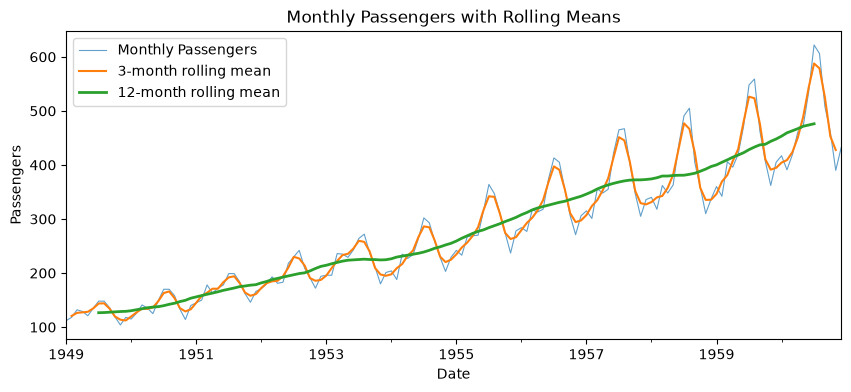

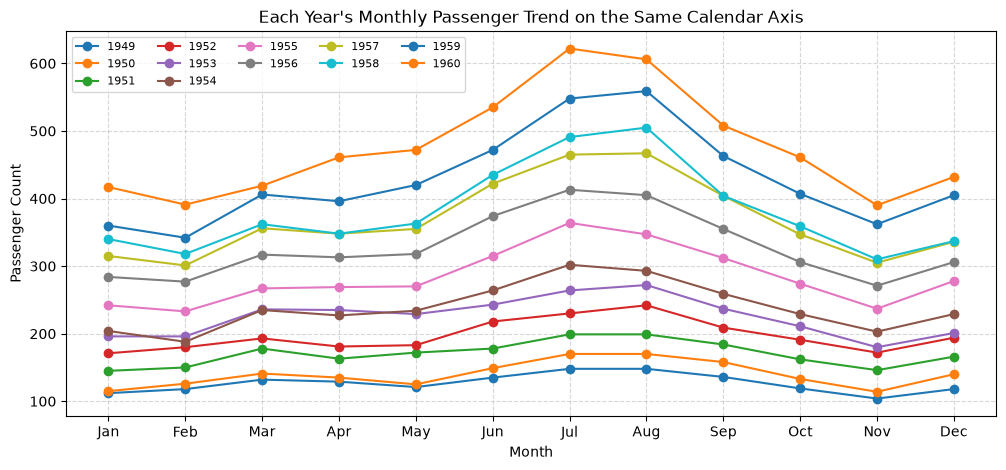

In [3]:
# --- Chart 1: Monthly Passengers with Rolling Means ---
fig, ax = plt.subplots(figsize=(10, 4))
# Plot original monthly passenger series
s.plot(ax=ax, lw=0.8, alpha=0.7, label="Monthly Passengers")
# Compute and plot 3-month centered rolling mean (captures short-term fluctuations)
s.rolling(3, center=True).mean().plot(ax=ax, lw=1.5, label="3-month rolling mean")
# Compute and plot 12-month centered rolling mean (captures long-term trend)
s.rolling(12, center=True).mean().plot(ax=ax, lw=2, label="12-month rolling mean")

ax.legend()
plt.title("Monthly Passengers with Rolling Means")
plt.xlabel("Date")
plt.ylabel("Passengers")
plt.show()

# --- Chart 2: Year-over-Year Seasonal Overlay ---
plt.figure(figsize=(12, 5))
# Group data by year and plot each year's monthly trajectory on a shared 1-12 calendar axis
for year, group in s.groupby(s.index.year):
    plt.plot(group.index.month, group.values, marker="o", label=str(year))

plt.title("Each Year's Monthly Passenger Trend on the Same Calendar Axis")
plt.xlabel("Month")
plt.ylabel(
    "Passenger Count"
)  # Customize x-axis ticks to show month names instead of integers 1-12
plt.xticks(
    range(1, 13),
    [
        "Jan",
        "Feb",
        "Mar",
        "Apr",
        "May",
        "Jun",
        "Jul",
        "Aug",
        "Sep",
        "Oct",
        "Nov",
        "Dec",
    ],
)
plt.legend(ncols=5, fontsize=8, loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

## 3. Stationarity Testing & Transformations

Time series models like ARIMA require stationarity (constant mean and variance over time). 
- We define a helper function `stationarity_report()` that combines the **Augmented Dickey-Fuller (ADF)** test (null hypothesis: non-stationary) and the **Kwiatkowski-Phillips-Schmidt-Shin (KPSS)** test (null hypothesis: stationary).
- We test multiple transformations (logs, differencing, moving average de-trending, and STL residuals) to find the ideal stationary transformation.


--- Stationarity Report ---
                             series    n   ADF p  KPSS p         verdict
0                          original  144  0.9919    0.01  NOT stationary
1                               log  144  0.4224    0.01  NOT stationary
2                log - rolling mean  133  0.0222    0.10      stationary
3                    log - EWM mean  144  0.0659    0.10  NOT stationary
4                       log diff(1)  143  0.0711    0.10  NOT stationary
5             log seasonal diff(12)  132  0.0724    0.10  NOT stationary
6                  log STL residual  144  0.0000    0.10      stationary
7   log diff(1) + seasonal diff(12)  131  0.0002    0.10      stationary
8  log - rolling mean, then diff(1)  132  0.0019    0.10      stationary
9   log STL deseasonalised, diff(1)  143  0.0000    0.10      stationary


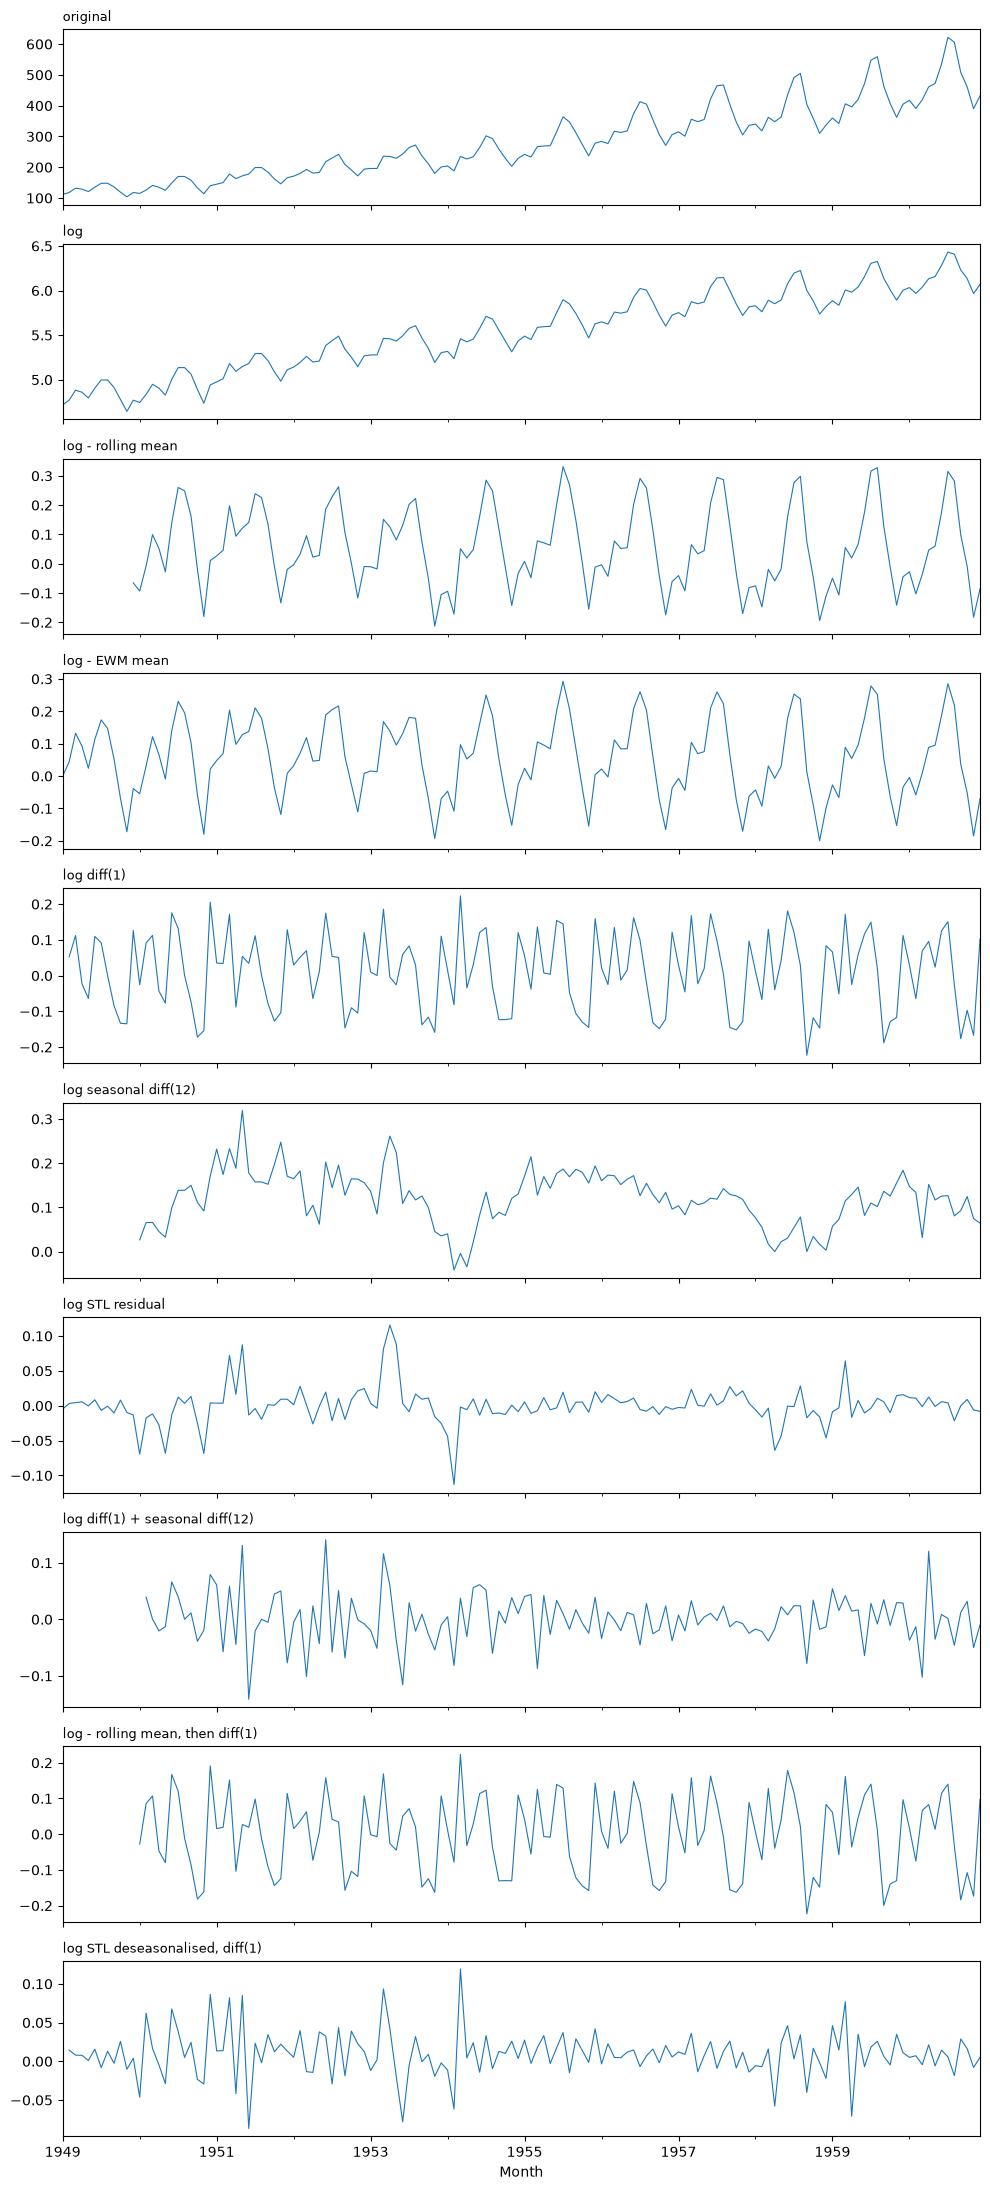

In [4]:
def stationarity_report(x, name):
    """Calculates ADF and KPSS p-values to determine if a series is stationary.
    Returns a dictionary summary with verdict.
    """
    x = x.dropna()
    # ADF test: p-value < 0.05 indicates rejection of non-stationarity
    adf_p = adfuller(x, autolag="AIC")[1]
    # KPSS test: p-value > 0.05 indicates failure to reject stationarity
    kpss_p = kpss(x, regression="c", nlags="auto")[1]

    # Series is stationary if ADF confirms unit root absence AND KPSS confirms trend stationarity
    verdict = (
        "stationary" if (adf_p < 0.05 and kpss_p > 0.05) else "NOT stationary"
    )
    return {
        "series": name,
        "n": len(x),
        "ADF p": round(adf_p, 4),
        "KPSS p": round(kpss_p, 4),
        "verdict": verdict,
    }

# Define constants for annual seasonality and window size
PERIOD = 12  # Yearly seasonality in monthly data
WINDOW = 12  # 12-month smoothing window

# Dictionary to store various transformed versions of the series
results = {}
results["original"] = s

# 1. Log transformation to stabilize multiplicative variance
log_s = np.log(s)
results[
    "log"
] = log_s  # 2. Subtract rolling mean to de-trend log series
results["log - rolling mean"] = log_s - log_s.rolling(WINDOW).mean()
# 3. Subtract Exponential Weighted Moving (EWM) mean
results["log - EWM mean"] = log_s - log_s.ewm(span=WINDOW, adjust=False).mean()
# 4. First difference of log series (removes trend)
results["log diff(1)"] = log_s.diff()
# 5. Seasonal difference of log series (removes seasonality)
results["log seasonal diff(12)"] = log_s.diff(PERIOD)

# 6. STL decomposition residual
stl = STL(log_s, period=PERIOD, robust=True).fit()
results["log STL residual"] = stl.resid

# 7. Combined first difference AND seasonal difference (Standard SARIMA transformation)
results["log diff(1) + seasonal diff(12)"] = log_s.diff().diff(PERIOD)

# 8. Rolling mean subtraction followed by first difference
results["log - rolling mean, then diff(1)"] = (
    log_s - log_s.rolling(WINDOW).mean()
).diff()

# 9. STL deseasonalised series, then first differenced
results["log STL deseasonalised, diff(1)"] = (stl.trend + stl.resid).diff()

# Generate and print the stationarity test report dataframe
report = pd.DataFrame([stationarity_report(v, k) for k, v in results.items()])
print("\n--- Stationarity Report ---")
print(report)

# Plot all transformed series side-by-side for visual inspection
fig, axes = plt.subplots(
    len(results), 1, figsize=(10, 2.2 * len(results)), sharex=True
)
for ax, (name, ser) in zip(axes, results.items()):
    ser.plot(ax=ax, lw=0.8)
    ax.set_title(name, fontsize=9, loc="left")
plt.tight_layout()
plt.show()

## 4. ACF / PACF Analysis

We plot the **Autocorrelation Function (ACF)** and **Partial Autocorrelation Function (PACF)** of the fully differenced stationary series (`log diff(1) + seasonal diff(12)`). These plots help identify potential Auto-Regressive ($p, P$) and Moving Average ($q, Q$) orders for our SARIMA model.

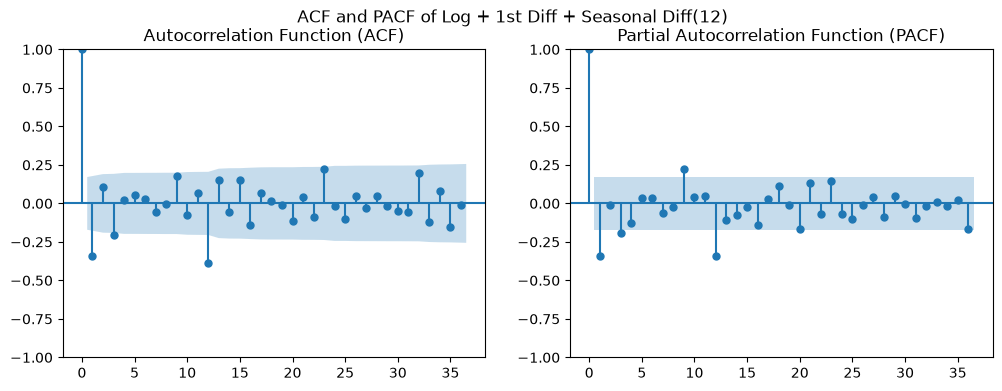

In [5]:
# Extract the best stationary differenced series and drop NaN values
best_diff = results["log diff(1) + seasonal diff(12)"].dropna()

# Create side-by-side subplots for ACF and PACF
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# ACF plot (determines MA order q)
plot_acf(best_diff, lags=36, ax=ax[0])
ax[0].set_title("Autocorrelation Function (ACF)")

# PACF plot (determines AR order p)
plot_pacf(best_diff, lags=36, ax=ax[1])
ax[1].set_title("Partial Autocorrelation Function (PACF)")

plt.suptitle("ACF and PACF of Log + 1st Diff + Seasonal Diff(12)")
plt.show()

## 5. STL Decomposition

We use **Seasonal-Trend decomposition using Loess (STL)** on the log-transformed series to cleanly separate the data into Trend, Seasonal, and Residual components. We also calculate the percentage share of variance explained by each component.

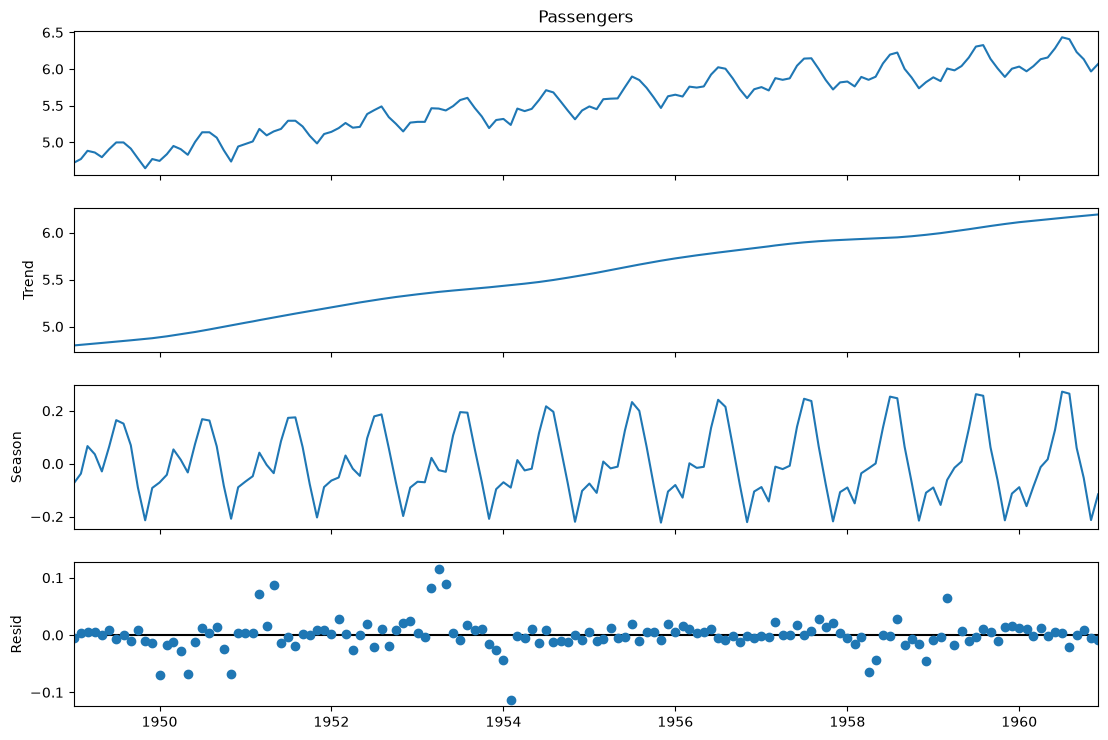


--- Variance Shares (Log-Transformed Series) ---
Seasonal share of variance: 8.28%
Trend share of variance: 91.04%
Residual share of variance: 0.36%


In [6]:
# Fit STL decomposition on log-transformed data with period=12 and robust fitting enabled
stl_log = STL(np.log(s), period=12, robust=True).fit()

# Plot the decomposition components (observed, trend, seasonal, residual)
fig = stl_log.plot()
fig.set_size_inches(12, 8)
plt.show()

# Calculate variance shares to understand which component dominates the data
var_total_log = np.log(s).var()
print(
    "\n--- Variance Shares (Log-Transformed Series) ---"
)  # Share of variance explained by seasonality
print(f"Seasonal share of variance: {stl_log.seasonal.var() / var_total_log:.2%}")
# Share of variance explained by the long-term trend
print(f"Trend share of variance: {stl_log.trend.var() / var_total_log:.2%}")
# Share of variance attributed to unexplained residuals
print(f"Residual share of variance: {stl_log.resid.var() / var_total_log:.2%}")

## 6. Train/Test Split & Grid Search

We split our data into a **training set** (up to Dec 1959) and a **test set** (year 1960). 
We then run an automated **grid search** over combinations of SARIMA parameters $(p, q, P, Q)$ with fixed differencing ($d=1, D=1, s=12$), selecting the model that minimizes the **Akaike Information Criterion (AIC)**.

In [7]:
# Resample data to monthly start and perform train/test split
m = s.resample("MS").mean()
m_train, m_test = (
    m[: "1959-12-01"],
    m["1960-01-01" :],
)

# Log-transform the training data for variance stabilization
log_train = np.log(m_train)

print("\n--- Grid Search for Optimal SARIMA Parameters ---")
best_model = None

# Iterate through combinations of p, q, P, Q parameters
for p, q, P, Q in itertools.product([0, 1, 2], [0, 1], [0, 1], [0, 1]):
    try:
        # Fit SARIMAX model on log training data with order (p,1,q) and seasonal order (P,1,Q,12)
        res = SARIMAX(
            log_train, order=(p, 1, q), seasonal_order=(P, 1, Q, 12)
        ).fit(disp=False, maxiter=200)

        # Track model with the lowest AIC (Akaike Information Criterion)
        if best_model is None or res.aic < best_model[0]:
            best_model = (res.aic, (p, 1, q), (P, 1, Q, 12), res)
    except Exception:
        pass  # Suppress individual convergence errors during grid search

# Unpack best model results
aic, order, seasonal_order, sarima = best_model
print(
    f"Best model found: SARIMAX{order}x{seasonal_order} with AIC: {aic:.2f}"
)


--- Grid Search for Optimal SARIMA Parameters ---
Best model found: SARIMAX(0, 1, 1)x(0, 1, 1, 12) with AIC: -441.25


## 7. Model Evaluation

We generate forecasts for the test period (year 1960), inverse-transform them back to original passenger scales via `np.exp()`, and evaluate performance using **Mean Absolute Error (MAE)** and **Root Mean Squared Error (RMSE)**.

In [8]:
def m_eval(pred, name):
    """Calculates MAE and RMSE between test actuals and predicted values."""
    e = m_test - pred
    return {
        "model": name,
        "MAE": round(e.abs().mean(), 2),
        "RMSE": round(np.sqrt((e ** 2).mean()), 2),
    }

# Forecast over the length of the test set
steps = len(m_test)
forecast_log = sarima.get_forecast(steps=steps)

# Exponentiate log forecasts to return to original passenger count scale
pred = np.exp(forecast_log.predicted_mean)
pred.index = m_test.index

# Evaluate predictions against actual test values
result_dict = m_eval(pred, f"Optimal SARIMAX{order}x{seasonal_order}")
m_results = pd.DataFrame([result_dict])

print("\n--- Test Set Evaluation Metrics ---")
print(m_results)


--- Test Set Evaluation Metrics ---
                                    model    MAE   RMSE
0  Optimal SARIMAX(0, 1, 1)x(0, 1, 1, 12)  13.26  18.59


## 8. Final Forecast & Visualization

Finally, we inspect the full statistical summary of our fitted SARIMAX model and plot the training data, test actuals, forecasted values, and 95% confidence intervals.


--- Model Statistical Summary ---
                                     SARIMAX Results                                      
Dep. Variable:                         Passengers   No. Observations:                  132
Model:             SARIMAX(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood                 223.627
Date:                            Mon, 09 Nov 2026   AIC                           -441.253
Time:                                    21:16:01   BIC                           -432.916
Sample:                                01-01-1949   HQIC                          -437.868
                                     - 12-01-1959                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.3485      0.081     -4.301      0.000      -0.507      -0.190


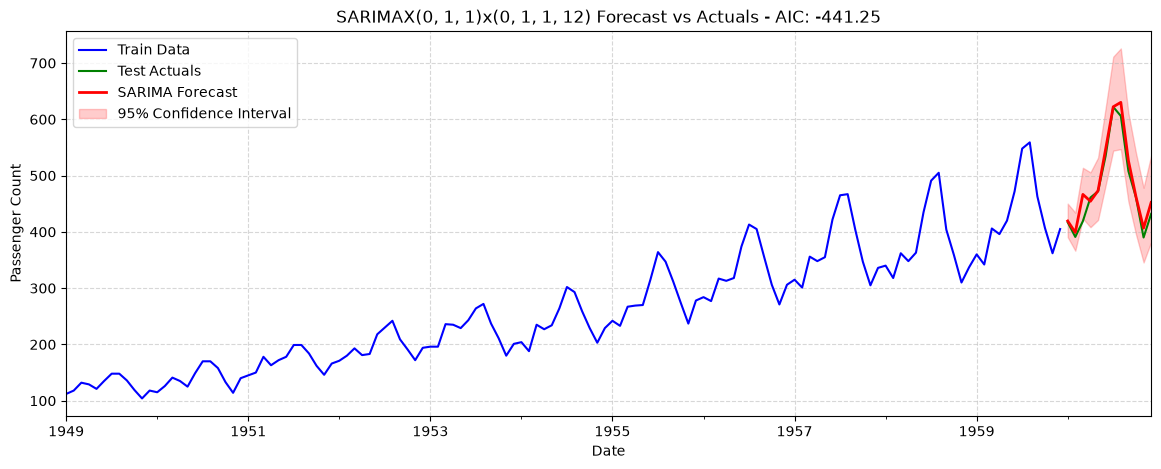

In [9]:
# Print full statistical summary of the fitted SARIMAX model
print("\n--- Model Statistical Summary ---")
print(sarima.summary())

# --- Visualization: Train, Test, Forecast, and Confidence Intervals ---
fig, ax = plt.subplots(figsize=(14, 5))

# Plot training data
m_train.plot(ax=ax, label="Train Data", color="blue")
# Plot test data actuals
m_test.plot(ax=ax, label="Test Actuals", color="green")
# Plot model forecast
pred.plot(ax=ax, label="SARIMA Forecast", color="red", lw=2)

# Extract and exponentiate 95% confidence intervals
cir = forecast_log.conf_int()
cir.index = m_test.index
cir = np.exp(cir)

# Fill confidence interval area
ax.fill_between(
    cir.index,
    cir.iloc[:, 0],
    cir.iloc[:, 1],
    color="red",
    alpha=0.2,
    label="95% Confidence Interval",
)

# Customize plot labels and legend
ax.set(
    title=f"SARIMAX{order}x{seasonal_order} Forecast vs Actuals - AIC: {aic:.2f}",
    xlabel="Date",
    ylabel="Passenger Count",
)
ax.legend(loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()